Nama : Candra Sya'bana P. G. <br>
NIM  : 60324042 <br>
Kelas: Visualisasi Data (A) <br>

# Praktikum

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/flights.csv"

df = pd.read_csv(url)
df = df.rename(columns={"year": "tahun", "passengers": "penumpang"})

df["tanggal"] = pd.to_datetime(
    df["tahun"].astype(str) + "-" + df["month"].astype(str).str[:3],
    format="%Y-%b")
df["bulan_ke"] = df["tanggal"].dt.month
df = df.sort_values("tanggal")

ts = df.set_index("tanggal")["penumpang"]
sns.set_theme(style="whitegrid")
print("Data siap:", len(ts), "bulan,",ts.index.min().strftime("%Y-%m"), "s.d.", ts.index.max().strftime("%Y-%m"))
print(ts.head())

Data siap: 144 bulan, 1949-01 s.d. 1960-12
tanggal
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Name: penumpang, dtype: int64


Line Chart dan Menandai Titik Penting

Text(0, 0.5, 'Penumpang (ribu)')

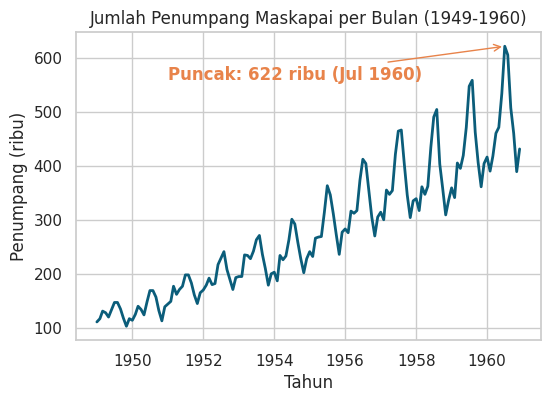

In [ ]:
puncak = ts.idxmax()
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(ts.index, ts.values, color="#0B5D7A", linewidth=2)

ax.annotate(f"Puncak: {ts.max()} ribu ({puncak:%b %Y})",
        xy=(puncak, ts.max()),
        xytext=(pd.Timestamp("1951-01-01"), 560),
        arrowprops={"arrowstyle": "->", "color": "#E8834A"},
        color="#E8834A", fontweight="bold")
ax.set_title("Jumlah Penumpang Maskapai per Bulan (1949-1960)")
ax.set_xlabel("Tahun")
ax.set_ylabel("Penumpang (ribu)")

Moving Average

tanggal
1949-12-01    126.7
1950-01-01    126.9
1950-02-01    127.6
Name: penumpang, dtype: float64


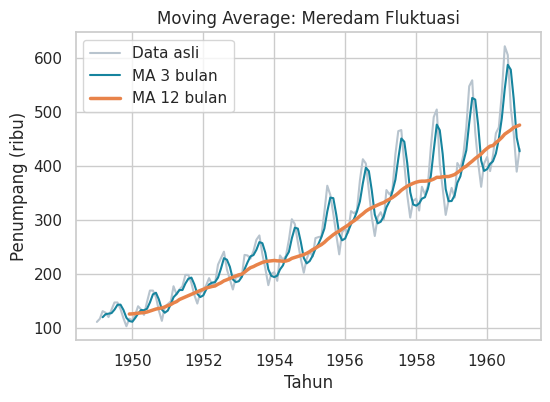

In [ ]:
ma3 = ts.rolling(window=3).mean()
ma12 = ts.rolling(window=12).mean()
print(ma12.dropna().head(3).round(1))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(ts, color="#B8C4CE", label="Data asli")
ax.plot(ma3, color="#16849E", label="MA 3 bulan")
ax.plot(ma12, color="#E8834A", linewidth=2.5, label="MA 12 bulan")
ax.set_title("Moving Average: Meredam Fluktuasi")
ax.set_xlabel("Tahun")
ax.set_ylabel("Penumpang (ribu)")
ax.legend()
plt.show()

Mendeteksi Tren: Garis Tren Linear

tahun
1949    126.7
1960    476.2
Name: penumpang, dtype: float64
Pertumbuhan rata-rata 1949-1960: 276%
Kemiringan tren: 2.66 ribu penumpang per bulan


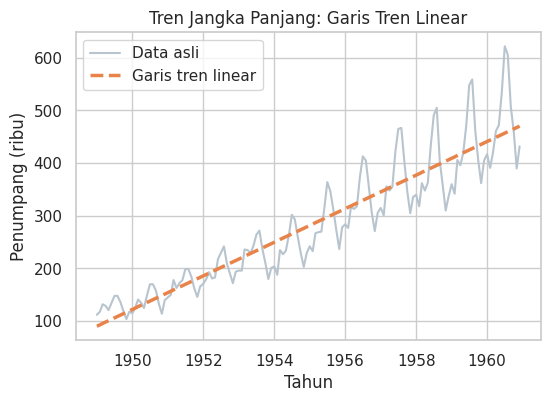

In [ ]:
tahunan = df.groupby("tahun")["penumpang"].mean()
print(tahunan.round(1).iloc[[0, -1]])
pertumbuhan = (tahunan.iloc[-1] / tahunan.iloc[0] - 1) * 100
print(f"Pertumbuhan rata-rata 1949-1960: {pertumbuhan:.0f}%")

x = np.arange(len(ts))
kemiringan, titik_awal = np.polyfit(x, ts.values, 1)
garis_tren = kemiringan * x + titik_awal
print(f"Kemiringan tren: {kemiringan:.2f} ribu penumpang per bulan")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(ts.index, ts.values, color="#B8C4CE", label="Data asli")
ax.plot(ts.index, garis_tren, color="#E8834A", linestyle="--",
        linewidth=2.5, label="Garis tren linear")
ax.set_title("Tren Jangka Panjang: Garis Tren Linear")
ax.set_xlabel("Tahun")
ax.set_ylabel("Penumpang (ribu)")
ax.legend()
plt.show()

Mendeteksi Musiman: Seasonal Plot

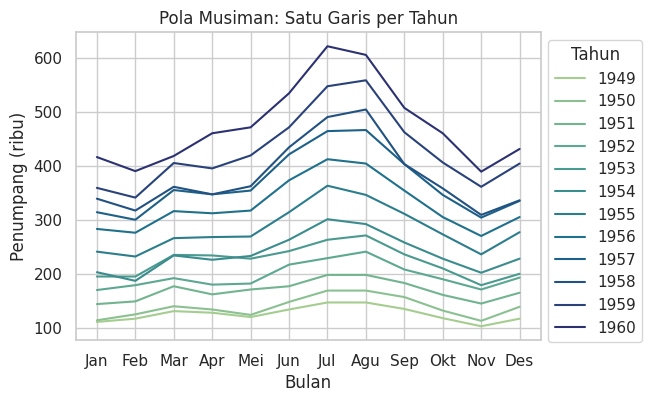

In [ ]:
nama_bulan = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun",
              "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

fig, ax = plt.subplots(figsize=(6, 4))
sns.lineplot(data=df, x="bulan_ke", y="penumpang", hue="tahun",
            palette="crest", legend="full", ax=ax)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(nama_bulan)
ax.set_title("Pola Musiman: Satu Garis per Tahun")
ax.set_xlabel("Bulan")
ax.set_ylabel("Penumpang (ribu)")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), title="Tahun")
plt.show()

Heatmap Tahun x Bulan

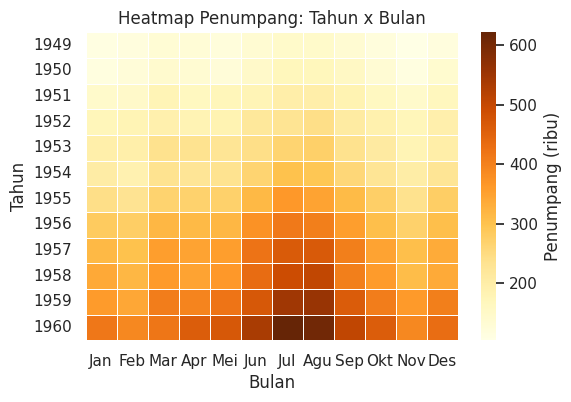

In [ ]:
tabel = df.pivot(index="tahun", columns="bulan_ke", values="penumpang")
tabel.columns = nama_bulan

fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(tabel, cmap="YlOrBr", linewidths=0.5,
           cbar_kws={"label": "Penumpang (ribu)"}, ax=ax)

ax.set_title("Heatmap Penumpang: Tahun x Bulan")
ax.set_xlabel("Bulan")
ax.set_ylabel("Tahun")
plt.show()

Dekomposisi Multiplikatif Sederhana

tanggal
1     0.91
2     0.88
3     1.01
4     0.98
5     0.98
6     1.11
7     1.23
8     1.22
9     1.06
10    0.92
11    0.80
12    0.90
Name: penumpang, dtype: float64


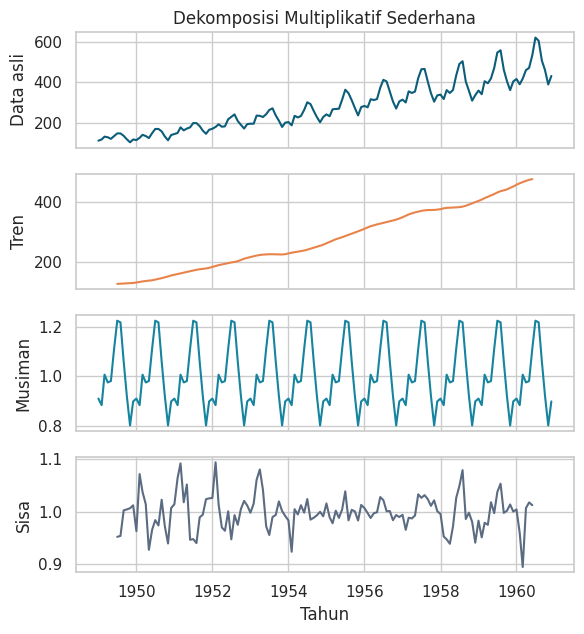

In [ ]:
tren = ts.rolling(window=12, center=True).mean()
tren = tren.rolling(window=2).mean().shift(-1)
rasio = ts / tren
indeks = rasio.groupby(rasio.index.month).mean()
indeks = indeks / indeks.mean()
print(indeks.round(2))

musiman = pd.Series(ts.index.month.map(indeks).to_numpy(), index=ts.index)
sisa = ts / (tren * musiman)

fig, axes = plt.subplots(4, 1, figsize=(6, 6.5), sharex=True)
komponen = [(ts, "Data asli", "#0B5D7A"), (tren, "Tren", "#E8834A"),
            (musiman, "Musiman", "#16849E"), (sisa, "Sisa", "#5B6B82")]

for ax, (seri, nama, warna) in zip(axes, komponen):
    ax.plot(seri, color=warna)
    ax.set_ylabel(nama)
axes[0].set_title("Dekomposisi Multiplikatif Sederhana")
axes[-1].set_xlabel("Tahun")
plt.tight_layout()
plt.show()

# Proyek Mini: Menjawab Tiga Pertanyaan dengan Data

Pertanyaan 1: Pertumbuhan Penumpang dan Garis Tren

**Grafik yang Tepat:** Line Chart Data Asli dengan Garis Tren Linear.

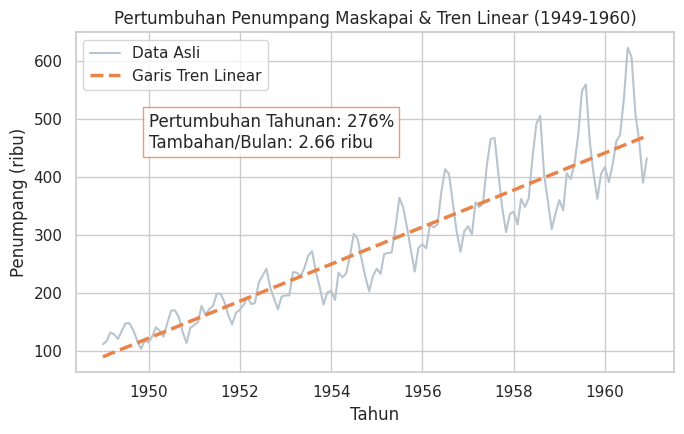

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(ts.index, ts.values, color="#B8C4CE", label="Data Asli")
ax.plot(ts.index, garis_tren, color="#E8834A", linestyle="--", linewidth=2.5, label="Garis Tren Linear")

# Menambahkan informasi angka di grafik
ax.text(pd.Timestamp("1950-01-01"), 450, f"Pertumbuhan Tahunan: {pertumbuhan:.0f}%\nTambahan/Bulan: {kemiringan:.2f} ribu",
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='#E8834A'))

ax.set_title("Pertumbuhan Penumpang Maskapai & Tren Linear (1949-1960)")
ax.set_xlabel("Tahun")
ax.set_ylabel("Penumpang (ribu)")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretasi:**

Rata-rata penumpang tahunan tumbuh sebesar **276%** dari tahun 1949 (126.7 ribu) ke tahun 1960 (476.2 ribu). Berdasarkan pemodelan garis tren linear, terdapat rata-rata tambahan penumpang sebanyak **2.66 ribu** orang setiap bulannya.

Pertanyaan 2: Analisis Pola Musiman Tinggi dan Rendah

**Grafik yang Tepat:** Bar Chart Indeks Musiman.

/tmp/ipykernel_429/3908263022.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_indeks, x='Bulan', y='Persentase_Tren', palette='viridis', ax=ax)


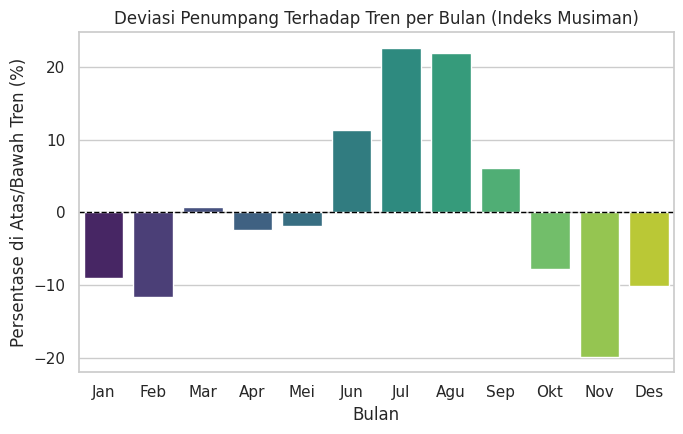

In [ ]:
# Membuat DataFrame indeks musiman untuk plotting
df_indeks = pd.DataFrame({
    'Bulan': nama_bulan,
    'Indeks': indeks.values
})
df_indeks['Persentase_Tren'] = (df_indeks['Indeks'] - 1) * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(data=df_indeks, x='Bulan', y='Persentase_Tren', palette='viridis', ax=ax)
ax.axhline(0, color='black', linestyle='--', linewidth=1)

ax.set_title("Deviasi Penumpang Terhadap Tren per Bulan (Indeks Musiman)")
ax.set_xlabel("Bulan")
ax.set_ylabel("Persentase di Atas/Bawah Tren (%)")
plt.tight_layout()
plt.show()

**Interpretasi:**

Penumpang paling banyak terjadi pada bulan **Juli** dengan jumlah **23% di atas tren**, sedangkan penumpang paling sedikit terjadi pada bulan **November** dengan jumlah **20% di bawah tren** jangka panjang.

Pertanyaan 3: Analisis Selisih Puncak-Lembah Tahunan

**Grafik yang Tepat:** Line Chart Selisih Nilai Maksimum dan Minimum (Puncak-Lembah) per Tahun.

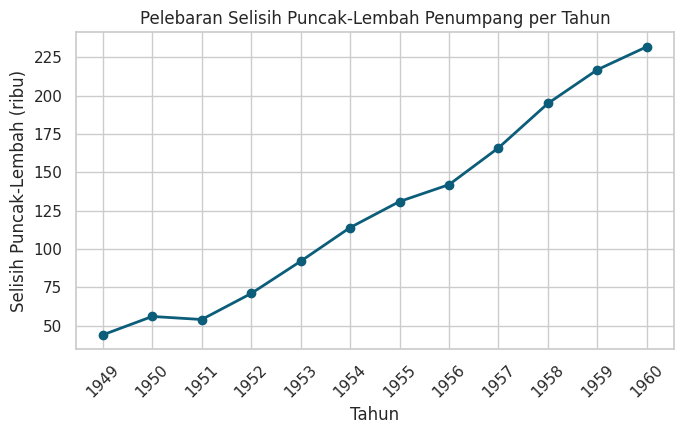

In [ ]:
stats_tahunan = df.groupby("tahun")["penumpang"].agg(["min", "max"])
stats_tahunan["selisih"] = stats_tahunan["max"] - stats_tahunan["min"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(stats_tahunan.index, stats_tahunan["selisih"], marker='o', color='#0B5D7A', linewidth=2)
ax.set_title("Pelebaran Selisih Puncak-Lembah Penumpang per Tahun")
ax.set_xlabel("Tahun")
ax.set_ylabel("Selisih Puncak-Lembah (ribu)")
ax.set_xticks(stats_tahunan.index)
ax.set_xticklabels(stats_tahunan.index, rotation=45)
plt.tight_layout()
plt.show()

**Interpretasi:**

Selisih antara puncak dan lembah dalam setahun semakin melebar secara signifikan dari **44 ribu** (1949) menjadi **215 ribu** (1960). Hal ini menunjukkan bahwa variasi musiman meningkat seiring dengan pertumbuhan tren, sehingga **model multiplikatif** adalah pilihan yang paling tepat.

# Latihan Mandiri

### Latihan 1

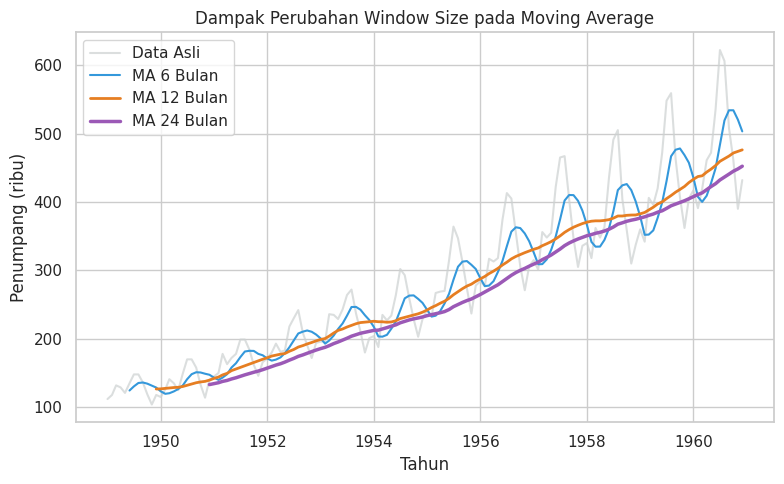

Jumlah nilai kosong (NaN):
- MA 6 Bulan  : 5 bulan
- MA 12 Bulan : 11 bulan
- MA 24 Bulan : 23 bulan


In [ ]:
ma6 = ts.rolling(window=6).mean()
ma12 = ts.rolling(window=12).mean()
ma24 = ts.rolling(window=24).mean()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(ts, color="#CCD1D1", label="Data Asli", alpha=0.7)
ax.plot(ma6, color="#3498DB", linewidth=1.5, label="MA 6 Bulan")
ax.plot(ma12, color="#E67E22", linewidth=2, label="MA 12 Bulan")
ax.plot(ma24, color="#9B59B6", linewidth=2.5, label="MA 24 Bulan")

ax.set_title("Dampak Perubahan Window Size pada Moving Average")
ax.set_xlabel("Tahun")
ax.set_ylabel("Penumpang (ribu)")
ax.legend()
plt.tight_layout()
plt.show()

# Analisis jumlah nilai kosong (null)
print(f"Jumlah nilai kosong (NaN):")
print(f"- MA 6 Bulan  : {ma6.isna().sum()} bulan")
print(f"- MA 12 Bulan : {ma12.isna().sum()} bulan")
print(f"- MA 24 Bulan : {ma24.isna().sum()} bulan")

### Latihan 2

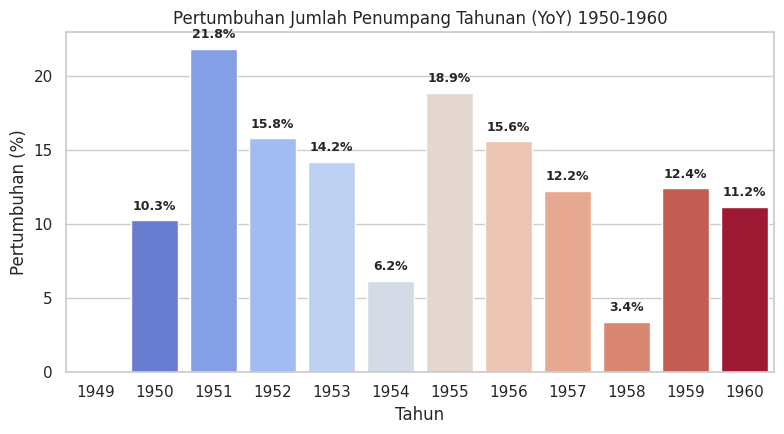

In [ ]:
total_tahunan = df.groupby("tahun")["penumpang"].sum()
pertumbuhan_yoy = total_tahunan.pct_change() * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=pertumbuhan_yoy.index, y=pertumbuhan_yoy.values, palette="coolwarm", ax=ax, hue=pertumbuhan_yoy.index, legend=False)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)

# Menambahkan label nilai di atas bar
for i, val in enumerate(pertumbuhan_yoy.values):
    if not np.isnan(val):
        ax.text(i, val + (0.5 if val > 0 else -1.5), f"{val:.1f}%", ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_title("Pertumbuhan Jumlah Penumpang Tahunan (YoY) 1950-1960")
ax.set_xlabel("Tahun")
ax.set_ylabel("Pertumbuhan (%)")
plt.tight_layout()
plt.show()

### Latihan 3

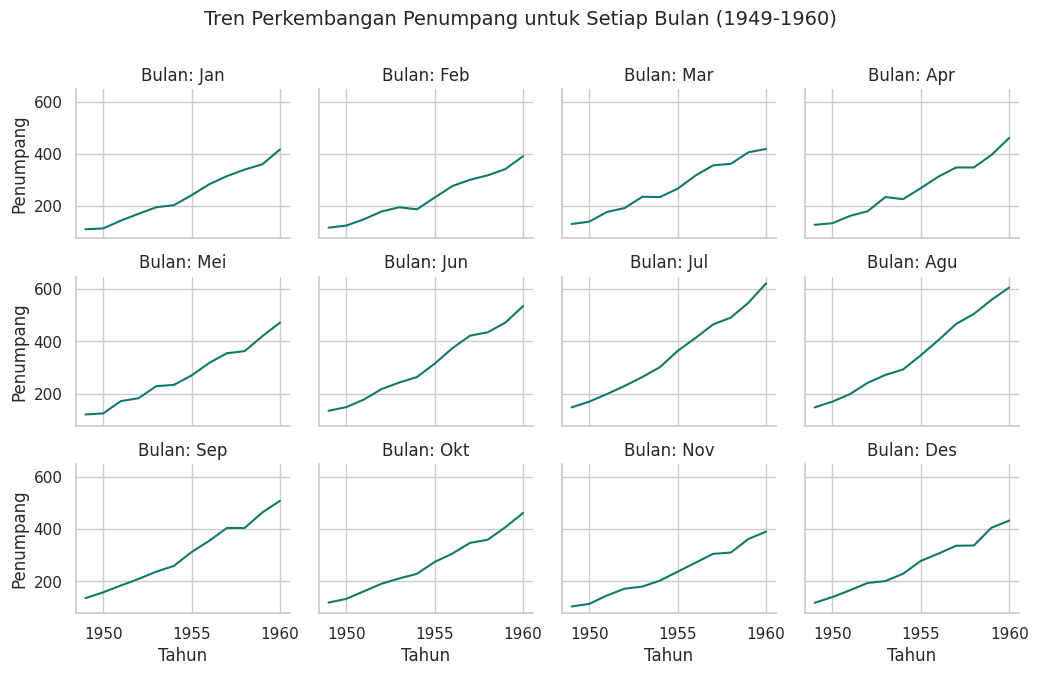

In [ ]:
# Membuat mapping nama bulan agar subplot lebih mudah dipahami
bulan_map = {i: nama for i, nama in enumerate(nama_bulan, 1)}
df['nama_bulan'] = df['bulan_ke'].map(bulan_map)

g = sns.relplot(
    data=df,
    x="tahun",
    y="penumpang",
    col="nama_bulan",
    col_wrap=4,
    kind="line",
    height=2.2,
    aspect=1.2,
    color="#117A65"
)
g.set_titles("Bulan: {col_name}")
g.set_axis_labels("Tahun", "Penumpang")
plt.subplots_adjust(top=0.9)
g.fig.suptitle("Tren Perkembangan Penumpang untuk Setiap Bulan (1949-1960)", fontsize=14, y=1.02)
plt.show()

### Latihan 4

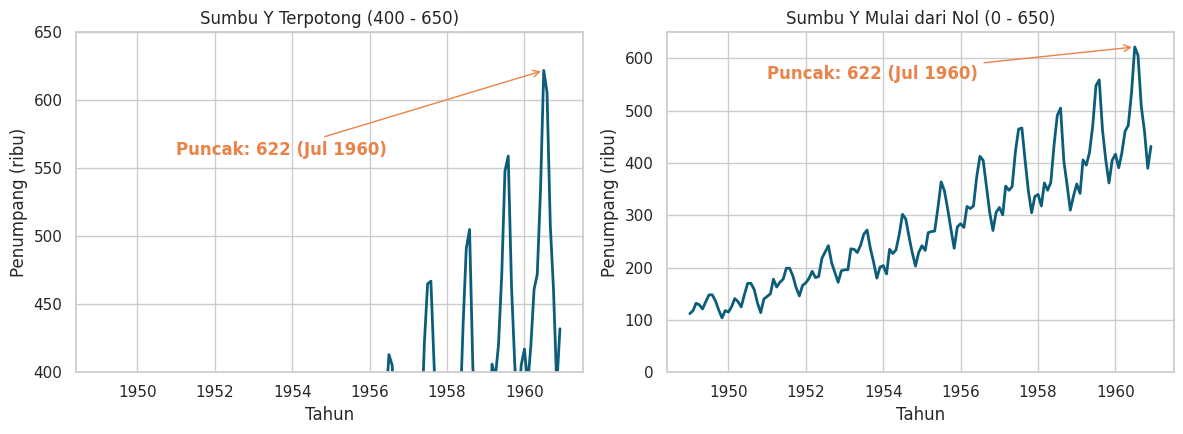

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Plot 1: Sumbu Y Terpotong (Truncated Y-Axis)
axes[0].plot(ts.index, ts.values, color="#0B5D7A", linewidth=2)
axes[0].annotate(f"Puncak: {ts.max()} ({puncak:%b %Y})",
            xy=(puncak, ts.max()),
            xytext=(pd.Timestamp("1951-01-01"), 560),
            arrowprops={"arrowstyle": "->", "color": "#E8834A"},
            color="#E8834A", fontweight="bold")
axes[0].set_ylim(400, 650)
axes[0].set_title("Sumbu Y Terpotong (400 - 650)")
axes[0].set_xlabel("Tahun")
axes[0].set_ylabel("Penumpang (ribu)")

# Plot 2: Sumbu Y Mulai dari Nol (Zero-Baseline Y-Axis)
axes[1].plot(ts.index, ts.values, color="#0B5D7A", linewidth=2)
axes[1].annotate(f"Puncak: {ts.max()} ({puncak:%b %Y})",
            xy=(puncak, ts.max()),
            xytext=(pd.Timestamp("1951-01-01"), 560),
            arrowprops={"arrowstyle": "->", "color": "#E8834A"},
            color="#E8834A", fontweight="bold")
axes[1].set_ylim(0, 650)
axes[1].set_title("Sumbu Y Mulai dari Nol (0 - 650)")
axes[1].set_xlabel("Tahun")
axes[1].set_ylabel("Penumpang (ribu)")

plt.tight_layout()
plt.show()

### Latihan 5

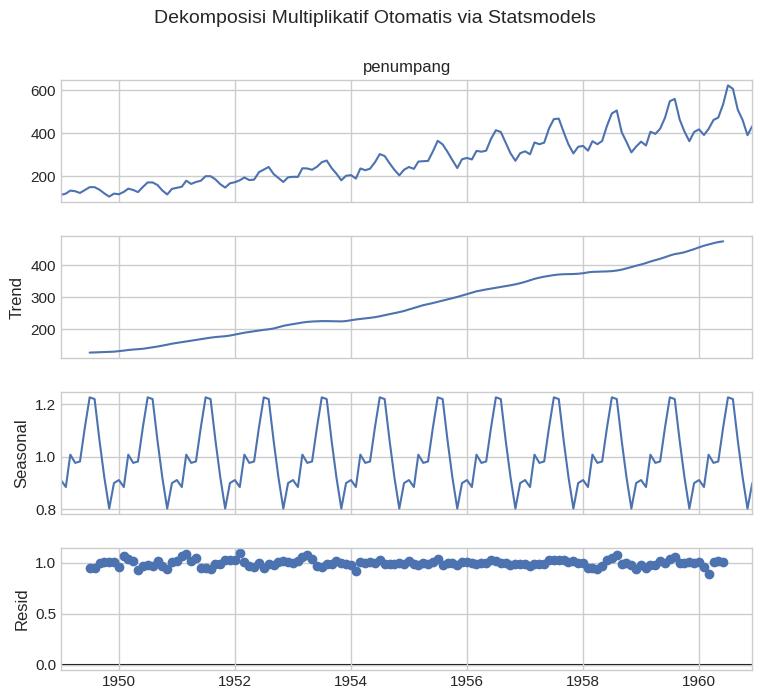

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

hasil = seasonal_decompose(ts, model="multiplicative", period=12)

# Kustomisasi visualisasi hasil dekomposisi
with plt.style.context('seaborn-v0_8-whitegrid'):
    fig = hasil.plot()
    fig.set_size_inches(8, 7)
    fig.suptitle("Dekomposisi Multiplikatif Otomatis via Statsmodels", y=1.02, fontsize=14)
    plt.show()

### Ringkasan

Berdasarkan rangkaian analisis data runtun waktu (*time series*) pada jumlah penumpang maskapai (1949-1960), beberapa poin penting yang dapat disimpulkan antara lain:

1. **Tren Pertumbuhan Kuat:** Terdapat tren kenaikan jangka panjang yang konsisten dan sangat signifikan dengan pertumbuhan rata-rata tahunan mencapai **276%** dari tahun 1949 ke 1960, dengan peningkatan rata-rata sekitar **2.66 ribu** penumpang per bulan.
2. **Karakteristik Musiman (*Seasonality*):** Pola musiman sangat kental terlihat dengan puncak kunjungan selalu terjadi pada musim liburan musim panas (**Juli dan Agustus**), sedangkan titik terendah aktivitas penerbangan secara konsisten berada pada bulan **November**.
3. **Kesesuaian Model Multiplikatif:** Melalui analisis selisih puncak-lembah tahunan yang semakin melebar dari tahun ke tahun, dikonfirmasi bahwa variabilitas musiman bersifat proporsional terhadap peningkatan tren. Hal ini memperkuat keputusan bahwa pemodelan dengan **pendekatan multiplikatif** jauh lebih akurat dan representatif dibandingkan model aditif.